# Model 1: SVM for LOS/NLOS classification

This notebook reproduces the **SVM** model from the paper (Section 3.3.3) on the new full-resolution preprocessed data in `../output_raw_full/`.

| | Paper | This notebook |
|---|---|---|
| Classifier | SVM, RBF kernel, probability estimation enabled | same |
| Input | 72 values per frame (mean \|I/Q\| over raw samples) | **3328 values per frame** (CSI amplitude, 64 antennas × 52 subcarriers) |
| Split | cluster-wise: 2 LOS + 3 NLOS train, 2 LOS + 2 NLOS test | same clusters |
| Normalisation | z-score per file (test files included) | **per-antenna normalisation** (`NORM = "antenna"`) + z-score fitted on training clusters only |
| Metrics | accuracy, confusion matrix, precision, recall, F1, ROC-AUC, PR curve, probability distribution | same, plus accuracy per test cluster |

**Why per-antenna normalisation:** the first version of the data used per-frame normalisation. With it, this SVM reached only 62.7% accuracy and classified **0% of LOS cluster 3** correctly. The pattern of which antennas are stronger depends on the user's direction relative to the array, not on LOS/NLOS. LOS 3's pattern correlates −0.39 to −0.47 with the training LOS clusters, so the SVM treated it as unknown and defaulted to NLOS. Dividing each antenna by its own mean removes that pattern and keeps the frequency shape (multipath). Step 2 checks that the data was preprocessed this way.

The notebook has two parts:
- **Part A (Steps 1–12): the paper's single split.** Train on LOS 1, LOS 2, NLOS 1–3; test on LOS 3, LOS 4, NLOS 4, NLOS 5.
- **Part B (Steps 13–18): all splits.** The same SVM is evaluated on every possible split, so the result doesn't depend on one lucky or unlucky choice of test clusters.

**Steps (Part A)**
1. Setup
2. Load the data and check the preprocessing settings
3. Train the SVM
4. Predict on the unseen test clusters
5. Classification metrics
6. Accuracy per test cluster
7. Confusion matrix
8. ROC curve
9. Precision–recall curve
10. Probability distribution
11. Comparison with the paper (Table 4)
12. Save the model and results

**Steps (Part B)**

13. List all splits
14. Load the per-cluster features
15. Evaluation function (z-score refitted per split)
16. Run all splits (progress saved after every split)
17. Summary: mean ± std, worst split, accuracy per held-out cluster
18. Plots and saved summary

## Step 1: Setup

The paper does not give the SVM hyperparameters, so scikit-learn's defaults are used: `C = 1.0`, `gamma = "scale"`.

**Running in Colab:** set `DATA_DIR` to the `output_raw_full` folder on your Drive.

In [25]:
import os
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.svm import SVC

DATA_DIR = "../output_raw_full"
RESULTS_DIR = "results"

C = 1.0            # paper does not specify; scikit-learn default
GAMMA = "scale"    # paper does not specify; scikit-learn default
SEED = 42

CLASS_NAMES = ["NLOS (0)", "LOS (1)"]

# chart colours (reference palette): one colour per class, text in neutral ink
COLOR_LOS = "#2a78d6"
COLOR_NLOS = "#eb6834"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "lines.linewidth": 2,
})

os.makedirs(RESULTS_DIR, exist_ok=True)

## Step 2: Load the data and check the preprocessing settings

`config.json` (written by `preprocess_raw.ipynb`) must show `norm = "antenna"` and `feature = "full"`. Otherwise, re-run the preprocessing first.

The frame-level datasets are used. Each row is one frame: 3328 amplitude values, z-scored with statistics from the training clusters.

| Set | Clusters |
|---|---|
| Train | LOS 1, LOS 2, NLOS 1, NLOS 2, NLOS 3 |
| Test (unseen) | LOS 3, LOS 4, NLOS 4, NLOS 5 |

In [26]:
with open(os.path.join(DATA_DIR, "config.json")) as f:
    prep = json.load(f)
print("preprocessing:", {k: prep.get(k) for k in ["feature", "norm", "n_features", "window", "stride", "skip_first_frames"]})
assert prep.get("norm") == "antenna", "data is not per-antenna normalised -- run preprocess_raw.ipynb with NORM = 'antenna'"
assert prep.get("feature") == "full", "expected FEATURE = 'full' (3328 values per frame)"
print()

X_train = np.load(os.path.join(DATA_DIR, "X_train_frames.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train_frames.npy"))
g_train = np.load(os.path.join(DATA_DIR, "groups_train_frames.npy"))

X_test = np.load(os.path.join(DATA_DIR, "X_test_frames.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test_frames.npy"))
g_test = np.load(os.path.join(DATA_DIR, "groups_test_frames.npy"))

for name, X, y, g in [("train", X_train, y_train, g_train), ("test", X_test, y_test, g_test)]:
    print(f"{name}: X={X.shape} {X.dtype}  LOS={int((y == 1).sum())}  NLOS={int((y == 0).sum())}")
    for c, n in zip(*np.unique(g, return_counts=True)):
        print(f"    {c:14s} {n:5d} frames")

preprocessing: {'feature': 'full', 'norm': 'antenna', 'n_features': 3328, 'window': 50, 'stride': 10, 'skip_first_frames': 200}

train: X=(29487, 3328) float32  LOS=15897  NLOS=13590
    LOS_cluster1    7939 frames
    LOS_cluster2    7958 frames
    NLOS_cluster1   5880 frames
    NLOS_cluster2   3853 frames
    NLOS_cluster3   3857 frames
test: X=(23529, 3328) float32  LOS=15811  NLOS=7718
    LOS_cluster3    7911 frames
    LOS_cluster4    7900 frames
    NLOS_cluster4   3856 frames
    NLOS_cluster5   3862 frames


## Step 3: Train the SVM

An SVM finds the separating boundary with the largest margin. With the RBF kernel, the boundary can be non-linear:

$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$

`probability=True` adds Platt scaling, which turns the SVM's decision score into a class probability. scikit-learn fits it with an internal 5-fold cross-validation on the training frames.

In [27]:
svm = SVC(kernel="rbf", C=C, gamma=GAMMA, probability=True, random_state=SEED)

t0 = time.time()
svm.fit(X_train, y_train)
train_time = time.time() - t0

print(f"training time: {train_time:.1f} s")
print("support vectors per class (NLOS, LOS):", svm.n_support_.tolist(), " total:", int(svm.n_support_.sum()))

training time: 103.7 s
support vectors per class (NLOS, LOS): [419, 254]  total: 673


## Step 4: Predict on the unseen test clusters

- `predict` gives the class label from the SVM's decision function. A frame is LOS when the decision score is > 0.
- `predict_proba` gives P(LOS) from Platt scaling; it is used for the ROC curve, the PR curve and the probability plot.

In [28]:
t0 = time.time()
y_pred = svm.predict(X_test)
p_los = svm.predict_proba(X_test)[:, 1]
pred_time = time.time() - t0

print(f"prediction time for {len(y_test)} frames: {pred_time:.1f} s")

prediction time for 23529 frames: 25.3 s


## Step 5: Classification metrics

In [29]:
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, p_los)
pr_auc = average_precision_score(y_test, p_los)

print(f"Accuracy : {acc:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}  (average precision, LOS as positive class)")
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)

Accuracy : 0.9938
ROC-AUC  : 0.9998
PR-AUC   : 0.9999  (average precision, LOS as positive class)

              precision    recall  f1-score   support

    NLOS (0)     0.9945    0.9865    0.9905      7718
     LOS (1)     0.9934    0.9973    0.9954     15811

    accuracy                         0.9938     23529
   macro avg     0.9940    0.9919    0.9929     23529
weighted avg     0.9938    0.9938    0.9938     23529



## Step 6: Accuracy per test cluster

Each test cluster is a separate unseen environment. A single overall accuracy can hide one cluster that fails, so each cluster is checked separately.

In [30]:
per_cluster = {}
print(f"{'cluster':14s} {'label':>5s} {'frames':>6s} {'accuracy':>9s} {'mean P(LOS)':>12s}")
for c in np.unique(g_test):
    m = g_test == c
    per_cluster[c] = {
        "label": int(y_test[m][0]),
        "frames": int(m.sum()),
        "accuracy": float(accuracy_score(y_test[m], y_pred[m])),
        "mean_p_los": float(p_los[m].mean()),
    }
    r = per_cluster[c]
    print(f"{c:14s} {r['label']:5d} {r['frames']:6d} {r['accuracy']:9.4f} {r['mean_p_los']:12.4f}")

cluster        label frames  accuracy  mean P(LOS)
LOS_cluster3       1   7911    1.0000       0.9937
LOS_cluster4       1   7900    0.9947       0.9864
NLOS_cluster4      0   3856    0.9899       0.0201
NLOS_cluster5      0   3862    0.9832       0.0203


## Step 7: Confusion matrix

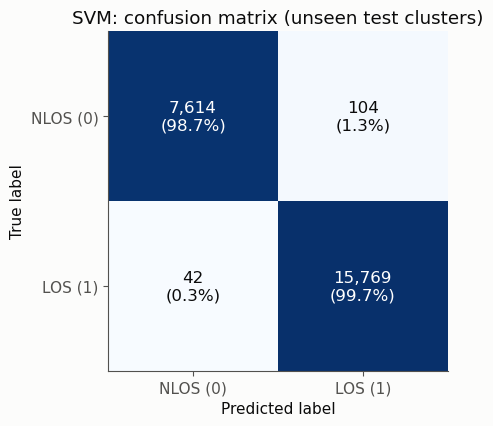

[[ 7614   104]
 [   42 15769]]


In [31]:
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)", ha="center", va="center",
                color="white" if cm_pct[i, j] > 60 else INK, fontsize=12)
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_yticks([0, 1], CLASS_NAMES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("SVM: confusion matrix (unseen test clusters)")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print(cm)

## Step 8: ROC curve

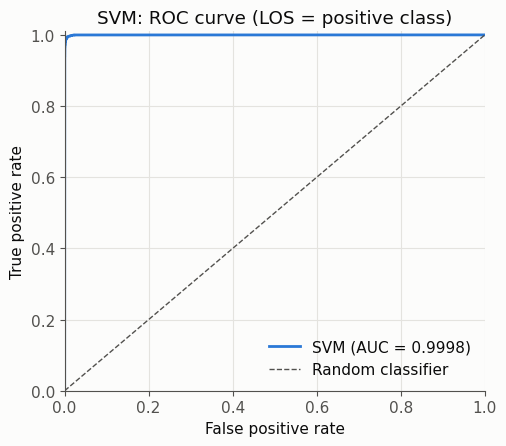

In [32]:
fpr, tpr, _ = roc_curve(y_test, p_los)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot(fpr, tpr, color=COLOR_LOS, label=f"SVM (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1, label="Random classifier")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("SVM: ROC curve (LOS = positive class)")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "roc_curve.png"), dpi=150)
plt.show()

## Step 9: Precision–recall curve

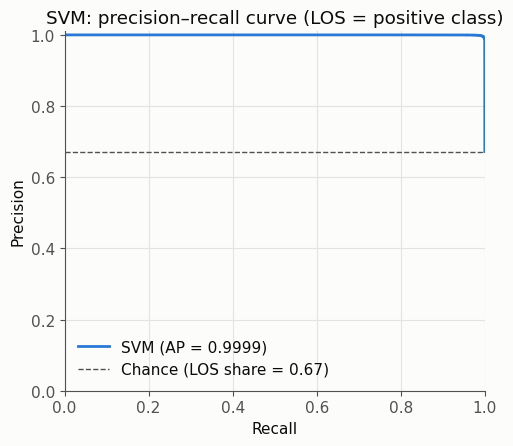

In [33]:
prec, rec, _ = precision_recall_curve(y_test, p_los)
baseline = y_test.mean()

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot(rec, prec, color=COLOR_LOS, label=f"SVM (AP = {pr_auc:.4f})")
ax.axhline(baseline, color=INK_2, linestyle="--", linewidth=1, label=f"Chance (LOS share = {baseline:.2f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("SVM: precision–recall curve (LOS = positive class)")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "pr_curve.png"), dpi=150)
plt.show()

## Step 10: Probability distribution

The histogram shows the predicted P(LOS) for frames that are truly NLOS and truly LOS. Good separation means NLOS frames sit near 0 and LOS frames near 1. The dashed line is the 0.5 threshold.

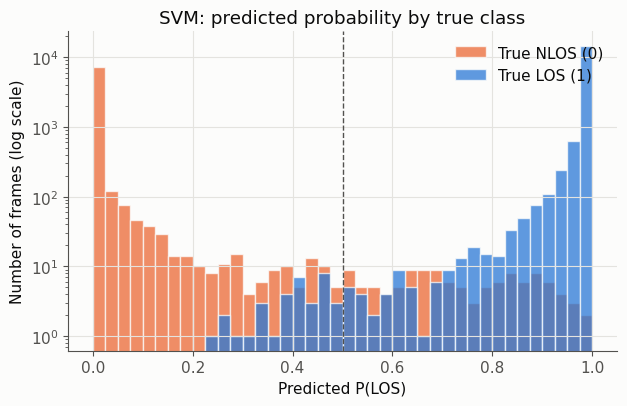

In [34]:
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.hist(p_los[y_test == 0], bins=bins, color=COLOR_NLOS, alpha=0.75, label="True NLOS (0)",
        edgecolor="#fcfcfb", linewidth=1)
ax.hist(p_los[y_test == 1], bins=bins, color=COLOR_LOS, alpha=0.75, label="True LOS (1)",
        edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0.5, color=INK_2, linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Predicted P(LOS)")
ax.set_ylabel("Number of frames (log scale)")
ax.set_title("SVM: predicted probability by true class")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "probability_distribution.png"), dpi=150)
plt.show()

## Step 11: Comparison with the paper (Table 4) and with the per-frame version

| Column | Data |
|---|---|
| `paper` | the paper's Table 4: 72 averaged raw-sample values per frame, z-score per file (test files included) |
| `per-frame (v1)` | this notebook on the first version of the data: 3328 values, per-frame normalisation (LOS 3 failed) |
| `this run` | this notebook on the current data: 3328 values, per-antenna normalisation |

The inputs differ, so the paper column is for reference only.

In [35]:
paper = {
    "accuracy": 0.82, "roc_auc": 0.9998,
    "NLOS (0)": {"precision": 0.65, "recall": 1.00, "f1-score": 0.79, "support": 8120},
    "LOS (1)": {"precision": 1.00, "recall": 0.73, "f1-score": 0.85, "support": 16213},
}
# first version of the data (NORM = "frame"), same SVM settings
v1 = {
    "accuracy": 0.6274, "roc_auc": 0.8230,
    "NLOS (0)": {"precision": 0.4682, "recall": 1.0000, "f1-score": 0.6378, "support": 7718},
    "LOS (1)": {"precision": 1.0000, "recall": 0.4455, "f1-score": 0.6164, "support": 15811},
}
v1_per_cluster = {"LOS_cluster3": 0.0000, "LOS_cluster4": 0.8916, "NLOS_cluster4": 1.0000, "NLOS_cluster5": 1.0000}

rows = [("Accuracy", paper["accuracy"], v1["accuracy"], acc),
        ("ROC-AUC", paper["roc_auc"], v1["roc_auc"], roc_auc)]
for cls in CLASS_NAMES:
    for k in ["precision", "recall", "f1-score"]:
        rows.append((f"{cls} {k}", paper[cls][k], v1[cls][k], report[cls][k]))
for cls in CLASS_NAMES:
    rows.append((f"{cls} support", paper[cls]["support"], v1[cls]["support"], report[cls]["support"]))

print(f"{'metric':22s} {'paper':>10s} {'per-frame (v1)':>15s} {'this run':>10s}")
for name, p, v, o in rows:
    fmt = "{:10.0f}" if "support" in name else "{:10.4f}"
    print(f"{name:22s} {fmt.format(p)} {fmt.format(v):>15s} {fmt.format(o)}")

print()
print(f"{'accuracy per cluster':22s} {'per-frame (v1)':>15s} {'this run':>10s}")
for c in per_cluster:
    print(f"{c:22s} {v1_per_cluster[c]:15.4f} {per_cluster[c]['accuracy']:10.4f}")

metric                      paper  per-frame (v1)   this run
Accuracy                   0.8200          0.6274     0.9938
ROC-AUC                    0.9998          0.8230     0.9998
NLOS (0) precision         0.6500          0.4682     0.9945
NLOS (0) recall            1.0000          1.0000     0.9865
NLOS (0) f1-score          0.7900          0.6378     0.9905
LOS (1) precision          1.0000          1.0000     0.9934
LOS (1) recall             0.7300          0.4455     0.9973
LOS (1) f1-score           0.8500          0.6164     0.9954
NLOS (0) support             8120            7718       7718
LOS (1) support             16213           15811      15811

accuracy per cluster    per-frame (v1)   this run
LOS_cluster3                    0.0000     1.0000
LOS_cluster4                    0.8916     0.9947
NLOS_cluster4                   1.0000     0.9899
NLOS_cluster5                   1.0000     0.9832


## Step 12: Save the model and results

| File | Contents |
|---|---|
| `results/svm_model.joblib` | the trained SVM (load with `joblib.load`) |
| `results/metrics.json` | all metrics, settings and timings |
| `results/predictions.npz` | `y_true`, `y_pred`, `p_los` and the cluster name for every test frame |
| `results/*.png` | the four figures |

In [36]:
joblib.dump(svm, os.path.join(RESULTS_DIR, "svm_model.joblib"))

np.savez(os.path.join(RESULTS_DIR, "predictions.npz"),
         y_true=y_test, y_pred=y_pred, p_los=p_los, groups=g_test)

metrics = {
    "model": "SVC(kernel='rbf')",
    "params": {"C": C, "gamma": GAMMA, "probability": True, "random_state": SEED},
    "data": {"dir": DATA_DIR, "n_features": int(X_train.shape[1]), "norm": prep.get("norm"),
             "n_train": int(len(y_train)), "n_test": int(len(y_test))},
    "accuracy": acc, "roc_auc": roc_auc, "pr_auc": pr_auc,
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "per_cluster": per_cluster,
    "n_support_vectors": svm.n_support_.tolist(),
    "train_time_s": train_time, "predict_time_s": pred_time,
}
with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

for fn in sorted(os.listdir(RESULTS_DIR)):
    print(f"{fn:28s} {os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1e6:7.2f} MB")

confusion_matrix.png            0.05 MB
metrics.json                    0.00 MB
pr_curve.png                    0.04 MB
predictions.npz                 1.46 MB
probability_distribution.png    0.05 MB
roc_curve.png                   0.06 MB
svm_model.joblib               17.93 MB


---
# Part B: evaluation on all splits

## Step 13: List all splits

With 4 LOS and 5 NLOS clusters, two protocols are used:

| Protocol | Test set per split | Train set per split | Number of splits |
|---|---|---|---|
| `lopo`: leave-one-pair-out | 1 LOS + 1 NLOS cluster | the other 7 clusters | 4 × 5 = **20** |
| `paper_style`: all paper-like splits | 2 LOS + 2 NLOS clusters | the other 2 LOS + 3 NLOS | C(4,2) × C(5,2) = 6 × 10 = **60** |

The paper's split (test = LOS 3, LOS 4, NLOS 4, NLOS 5) is one of the 60 `paper_style` splits.

**Settings:**
- `PROTOCOLS`: which protocols to run.
- `TRAIN_SUBSAMPLE`: `None` uses **all** training frames of each split. Set a number, for example `10000`, for a much faster run; this changed accuracy by less than 0.1% on the paper's split.

**Runtime with all frames** (estimate for this Mac): about 1 minute per split, so about **20 min for `lopo`** and **about 1 h for `paper_style`**. Progress is saved after each split. If the run stops, run Step 16 again and it continues where it left off.

In [37]:
import itertools

LOS_CLUSTERS = ["LOS_cluster1", "LOS_cluster2", "LOS_cluster3", "LOS_cluster4"]
NLOS_CLUSTERS = ["NLOS_cluster1", "NLOS_cluster2", "NLOS_cluster3", "NLOS_cluster4", "NLOS_cluster5"]
ALL_CLUSTERS = LOS_CLUSTERS + NLOS_CLUSTERS
PAPER_TEST = ["LOS_cluster3", "LOS_cluster4", "NLOS_cluster4", "NLOS_cluster5"]

PROTOCOLS = ["lopo", "paper_style"]   # run both; remove one to save time
TRAIN_SUBSAMPLE = None                # None = all training frames; e.g. 10000 for a fast run

short = lambda c: c.replace("_cluster", "")

def make_splits(protocol):
    if protocol == "lopo":
        tests = [[l, n] for l in LOS_CLUSTERS for n in NLOS_CLUSTERS]
    elif protocol == "paper_style":
        tests = [list(ls) + list(ns) for ls in itertools.combinations(LOS_CLUSTERS, 2)
                 for ns in itertools.combinations(NLOS_CLUSTERS, 2)]
    else:
        raise ValueError(protocol)
    splits = []
    for test in tests:
        train = [c for c in ALL_CLUSTERS if c not in test]
        splits.append({"name": "test=" + "+".join(short(c) for c in test), "train": train, "test": test})
    return splits

SPLITS = {p: make_splits(p) for p in PROTOCOLS}
for p, splits in SPLITS.items():
    print(f"{p}: {len(splits)} splits")
    for i, sp in enumerate(splits, 1):
        mark = "   <- paper split" if sorted(sp["test"]) == sorted(PAPER_TEST) else ""
        print(f"  {i:2d}. train={'+'.join(short(c) for c in sp['train']):38s} {sp['name']}{mark}")

lopo: 20 splits
   1. train=LOS2+LOS3+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS1+NLOS1
   2. train=LOS2+LOS3+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS1+NLOS2
   3. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS1+NLOS3
   4. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS1+NLOS4
   5. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS4 test=LOS1+NLOS5
   6. train=LOS1+LOS3+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS2+NLOS1
   7. train=LOS1+LOS3+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS2+NLOS2
   8. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS2+NLOS3
   9. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS2+NLOS4
  10. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS4 test=LOS2+NLOS5
  11. train=LOS1+LOS2+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS3+NLOS1
  12. train=LOS1+LOS2+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS3+NLOS2
  13. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS3+NLOS3
  14. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS3+NLOS4
  15. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS3+N

## Step 14: Load the per-cluster features

Each split has different training clusters, so the z-score must be fitted again on each split's training clusters. The ready-made `X_*_frames.npy` files can't be used here, because their scaler was fitted on the paper's training clusters. Instead, the per-cluster features saved **before the z-score** in `../output_raw_full/clusters/` are used (about 0.7 GB in memory).

In [38]:
CLUSTER_DIR = os.path.join(DATA_DIR, "clusters")
with open(os.path.join(CLUSTER_DIR, "index.json")) as f:
    cidx = json.load(f)
assert cidx["norm"] == "antenna" and not cidx["zscore_applied"], "re-run preprocess_raw.ipynb with NORM = 'antenna'"

cluster_X = {c: np.load(os.path.join(CLUSTER_DIR, cidx["clusters"][c]["features_file"])) for c in ALL_CLUSTERS}
cluster_y = {c: cidx["clusters"][c]["label"] for c in ALL_CLUSTERS}
for c in ALL_CLUSTERS:
    print(f"{c:14s} label={cluster_y[c]}  X={cluster_X[c].shape}")

LOS_cluster1   label=1  X=(7939, 3328)
LOS_cluster2   label=1  X=(7958, 3328)
LOS_cluster3   label=1  X=(7911, 3328)
LOS_cluster4   label=1  X=(7900, 3328)
NLOS_cluster1  label=0  X=(5880, 3328)
NLOS_cluster2  label=0  X=(3853, 3328)
NLOS_cluster3  label=0  X=(3857, 3328)
NLOS_cluster4  label=0  X=(3856, 3328)
NLOS_cluster5  label=0  X=(3862, 3328)


## Step 15: Evaluation function

For one split:
1. stack the training clusters, optionally subsample them (`TRAIN_SUBSAMPLE`);
2. fit the z-score **on the training frames only** and apply it to the training and test frames;
3. train the SVM with the same settings as Part A (RBF, `C`, `gamma`);
4. predict the test frames and compute accuracy, macro-F1, ROC-AUC, recall per class and accuracy per test cluster.

`probability=True` is left out here, because Platt scaling takes about 5 times longer. ROC-AUC uses the SVM's decision score instead, which gives the same ranking.

In [39]:
from sklearn.metrics import f1_score, recall_score

def evaluate_split(split, seed=SEED):
    rng = np.random.default_rng(seed)
    Xtr = np.concatenate([cluster_X[c] for c in split["train"]])
    ytr = np.concatenate([np.full(len(cluster_X[c]), cluster_y[c], dtype=np.int8) for c in split["train"]])
    if TRAIN_SUBSAMPLE and TRAIN_SUBSAMPLE < len(ytr):
        keep = np.sort(rng.choice(len(ytr), TRAIN_SUBSAMPLE, replace=False))
        Xtr, ytr = Xtr[keep], ytr[keep]

    mu = Xtr.mean(axis=0)
    sd = Xtr.std(axis=0) + 1e-8
    Xtr = (Xtr - mu) / sd

    model = SVC(kernel="rbf", C=C, gamma=GAMMA)
    t0 = time.time()
    model.fit(Xtr, ytr)
    fit_s = time.time() - t0
    del Xtr

    y_true, y_hat, score, per_cluster = [], [], [], {}
    for c in split["test"]:
        Xte = (cluster_X[c] - mu) / sd
        d = model.decision_function(Xte)
        p = (d > 0).astype(np.int8)
        yt = np.full(len(p), cluster_y[c], dtype=np.int8)
        per_cluster[c] = float((p == yt).mean())
        y_true.append(yt); y_hat.append(p); score.append(d)
    y_true, y_hat, score = np.concatenate(y_true), np.concatenate(y_hat), np.concatenate(score)

    return {
        "name": split["name"], "train": split["train"], "test": split["test"],
        "n_train": int(len(ytr)), "n_test": int(len(y_true)),
        "accuracy": float((y_hat == y_true).mean()),
        "macro_f1": float(f1_score(y_true, y_hat, average="macro")),
        "roc_auc": float(roc_auc_score(y_true, score)),
        "recall_los": float(recall_score(y_true, y_hat, pos_label=1)),
        "recall_nlos": float(recall_score(y_true, y_hat, pos_label=0)),
        "per_cluster_accuracy": per_cluster,
        "n_support_vectors": int(model.n_support_.sum()),
        "fit_seconds": fit_s,
    }

## Step 16: Run all splits

Results are appended to `results/splits_<protocol>.jsonl`, one line per split. Splits that are already in the file are skipped, so the run can be resumed after a stop. To start over, delete those files.

In [40]:
def load_done(path):
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return {r["name"]: r for r in (json.loads(line) for line in f if line.strip())}

ALL_RESULTS = {}
for protocol, splits in SPLITS.items():
    path = os.path.join(RESULTS_DIR, f"splits_{protocol}.jsonl")
    done = load_done(path)
    print(f"=== {protocol}: {len(splits)} splits ({len(done)} already done)")
    t_start = time.time()
    for i, sp in enumerate(splits, 1):
        if sp["name"] in done:
            continue
        r = evaluate_split(sp)
        with open(path, "a") as f:
            f.write(json.dumps(r) + "\n")
        done[r["name"]] = r
        print(f"  [{i:2d}/{len(splits)}] {r['name']:32s} acc={r['accuracy']:.4f}  macro-F1={r['macro_f1']:.4f}  "
              f"AUC={r['roc_auc']:.4f}  ({r['fit_seconds']:.0f}s fit, {time.time() - t_start:.0f}s total)")
    ALL_RESULTS[protocol] = [done[sp["name"]] for sp in splits]

=== lopo: 20 splits (0 already done)
  [ 1/20] test=LOS1+NLOS1                  acc=0.9305  macro-F1=0.9301  AUC=0.9997  (17s fit, 27s total)
  [ 2/20] test=LOS1+NLOS2                  acc=0.9153  macro-F1=0.9090  AUC=1.0000  (18s fit, 53s total)
  [ 3/20] test=LOS1+NLOS3                  acc=0.8405  macro-F1=0.8120  AUC=0.9308  (13s fit, 73s total)
  [ 4/20] test=LOS1+NLOS4                  acc=0.9286  macro-F1=0.9224  AUC=0.9940  (15s fit, 95s total)
  [ 5/20] test=LOS1+NLOS5                  acc=0.9199  macro-F1=0.9134  AUC=0.9957  (15s fit, 118s total)
  [ 6/20] test=LOS2+NLOS1                  acc=0.7857  macro-F1=0.7848  AUC=0.9863  (14s fit, 140s total)
  [ 7/20] test=LOS2+NLOS2                  acc=0.7509  macro-F1=0.7485  AUC=0.9974  (15s fit, 163s total)
  [ 8/20] test=LOS2+NLOS3                  acc=0.7984  macro-F1=0.7804  AUC=0.9088  (14s fit, 183s total)
  [ 9/20] test=LOS2+NLOS4                  acc=0.7626  macro-F1=0.7592  AUC=0.9400  (12s fit, 201s total)
  [10/20] tes

## Step 17: Summary

- **Mean ± std over splits** is the main number to report. The worst split shows how badly the model can do on an unlucky set of environments.
- **Accuracy of each held-out cluster**, averaged over every split where it was in the test set, shows which environments are hard.
- For `paper_style`, the paper's split is ranked among all 60 to show whether it is typical.

In [41]:
SUMMARY = {}
for protocol, res in ALL_RESULTS.items():
    acc = np.array([r["accuracy"] for r in res])
    f1 = np.array([r["macro_f1"] for r in res])
    auc = np.array([r["roc_auc"] for r in res])
    worst = res[int(acc.argmin())]
    print(f"=== {protocol} ({len(res)} splits)")
    print(f"  accuracy : {acc.mean():.4f} ± {acc.std():.4f}   min {acc.min():.4f}   max {acc.max():.4f}")
    print(f"  macro-F1 : {f1.mean():.4f} ± {f1.std():.4f}")
    print(f"  ROC-AUC  : {auc.mean():.4f} ± {auc.std():.4f}")
    print(f"  worst split: {worst['name']}  (acc {worst['accuracy']:.4f})")

    held = {c: [r["per_cluster_accuracy"][c] for r in res if c in r["per_cluster_accuracy"]] for c in ALL_CLUSTERS}
    held = {c: v for c, v in held.items() if v}
    print("  accuracy of each cluster when held out (mean / worst / number of splits):")
    for c in held:
        print(f"    {c:14s} {np.mean(held[c]):.4f} / {np.min(held[c]):.4f} / {len(held[c])}")

    entry = {"n_splits": len(res),
             "accuracy_mean": float(acc.mean()), "accuracy_std": float(acc.std()),
             "accuracy_min": float(acc.min()), "accuracy_max": float(acc.max()),
             "macro_f1_mean": float(f1.mean()), "macro_f1_std": float(f1.std()),
             "roc_auc_mean": float(auc.mean()), "roc_auc_std": float(auc.std()),
             "worst_split": worst["name"],
             "held_out_cluster_accuracy": {c: {"mean": float(np.mean(v)), "min": float(np.min(v)), "n": len(v)}
                                           for c, v in held.items()}}
    paper = next((r for r in res if sorted(r["test"]) == sorted(PAPER_TEST)), None)
    if paper is not None:
        rank = int((acc > paper["accuracy"]).sum()) + 1
        print(f"  paper's split: acc {paper['accuracy']:.4f}, rank {rank} of {len(res)} (1 = best)")
        entry["paper_split_accuracy"] = paper["accuracy"]
        entry["paper_split_rank"] = rank
    SUMMARY[protocol] = entry
    print()

=== lopo (20 splits)
  accuracy : 0.9086 ± 0.0906   min 0.7509   max 1.0000
  macro-F1 : 0.9022 ± 0.0938
  ROC-AUC  : 0.9857 ± 0.0262
  worst split: test=LOS2+NLOS2  (acc 0.7509)
  accuracy of each cluster when held out (mean / worst / number of splits):
    LOS_cluster1   0.8908 / 0.8742 / 5
    LOS_cluster2   0.6720 / 0.6273 / 5
    LOS_cluster3   1.0000 / 1.0000 / 5
    LOS_cluster4   0.9979 / 0.9963 / 5
    NLOS_cluster1  1.0000 / 1.0000 / 4
    NLOS_cluster2  1.0000 / 1.0000 / 4
    NLOS_cluster3  0.7174 / 0.6907 / 4
    NLOS_cluster4  0.9877 / 0.9860 / 4
    NLOS_cluster5  0.9904 / 0.9845 / 4

=== paper_style (60 splits)
  accuracy : 0.9008 ± 0.0706   min 0.7408   max 0.9975
  macro-F1 : 0.8953 ± 0.0706
  ROC-AUC  : 0.9847 ± 0.0169
  worst split: test=LOS1+LOS2+NLOS2+NLOS5  (acc 0.7408)
  accuracy of each cluster when held out (mean / worst / number of splits):
    LOS_cluster1   0.8440 / 0.6773 / 30
    LOS_cluster2   0.6631 / 0.5065 / 30
    LOS_cluster3   1.0000 / 0.9999 / 30


## Step 18: Plots and saved summary

1. **Accuracy of every split**, sorted. For `paper_style`, the paper's split is highlighted.
2. **Accuracy of each cluster when held out:** mean, with the range from worst to best split.

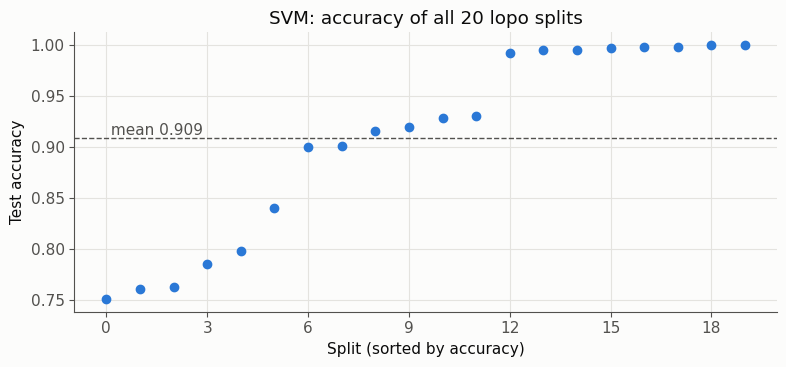

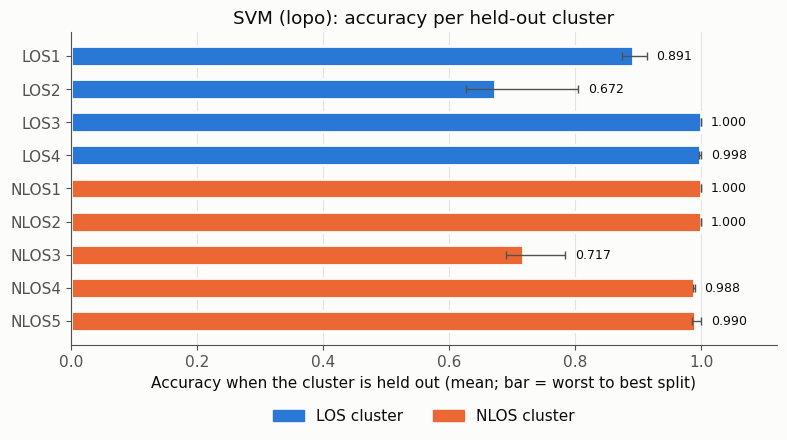

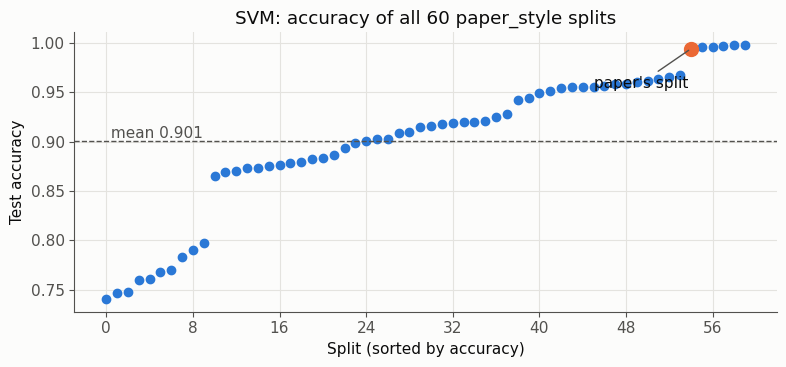

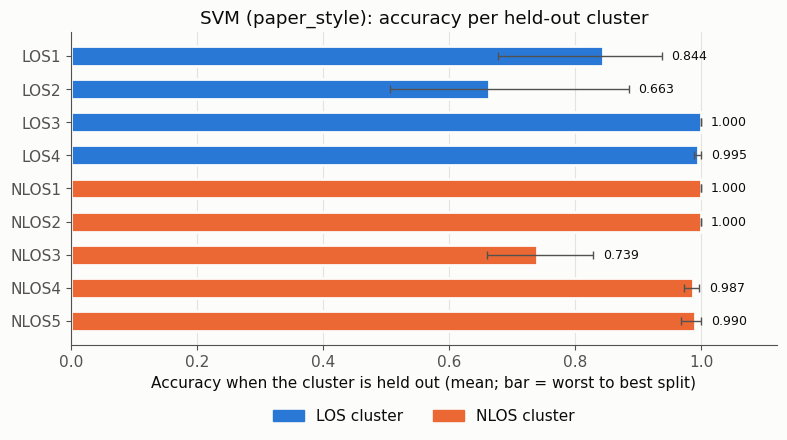

saved: results/splits_summary.json


In [42]:
for protocol, res in ALL_RESULTS.items():
    acc = np.array([r["accuracy"] for r in res])
    order = np.argsort(acc)
    is_paper = np.array([sorted(r["test"]) == sorted(PAPER_TEST) for r in res])[order]

    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(np.arange(len(acc)), acc[order], "o", color=COLOR_LOS, markersize=6)
    if is_paper.any():
        k = int(np.where(is_paper)[0][0])
        ax.plot(k, acc[order][k], "o", color=COLOR_NLOS, markersize=10)
        ax.annotate("paper's split", (k, acc[order][k]), xytext=(0, -62), textcoords="offset points",
                    ha="center", color=INK, arrowprops={"arrowstyle": "-", "color": INK_2})
    ax.axhline(acc.mean(), color=INK_2, linestyle="--", linewidth=1)
    ax.text(0, acc.mean(), f" mean {acc.mean():.3f}", va="bottom", color=INK_2)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("Split (sorted by accuracy)")
    ax.set_ylabel("Test accuracy")
    ax.set_title(f"SVM: accuracy of all {len(acc)} {protocol} splits")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS_DIR, f"splits_{protocol}_accuracy.png"), dpi=150)
    plt.show()

    held = SUMMARY[protocol]["held_out_cluster_accuracy"]
    shown = [c for c in ALL_CLUSTERS if c in held]
    means = np.array([held[c]["mean"] for c in shown])
    mins = np.array([held[c]["min"] for c in shown])
    maxs = np.array([max(r["per_cluster_accuracy"][c] for r in res if c in r["per_cluster_accuracy"]) for c in shown])
    colors = [COLOR_LOS if c.startswith("LOS") else COLOR_NLOS for c in shown]

    fig, ax = plt.subplots(figsize=(8, 4.6))
    y = np.arange(len(shown))
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.barh(y, means, color=colors, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    ax.errorbar(means, y, xerr=[means - mins, maxs - means], fmt="none", ecolor=INK_2, capsize=3, linewidth=1)
    for yi, m, hi in zip(y, means, maxs):
        ax.text(hi + 0.015, yi, f"{m:.3f}", va="center", color=INK, fontsize=9)
    ax.set_yticks(y, [short(c) for c in shown])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Accuracy when the cluster is held out (mean; bar = worst to best split)")
    ax.set_title(f"SVM ({protocol}): accuracy per held-out cluster")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR_LOS), plt.Rectangle((0, 0), 1, 1, color=COLOR_NLOS)],
              labels=["LOS cluster", "NLOS cluster"], frameon=False, ncol=2,
              loc="upper center", bbox_to_anchor=(0.5, -0.16))
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS_DIR, f"splits_{protocol}_per_cluster.png"), dpi=150)
    plt.show()

with open(os.path.join(RESULTS_DIR, "splits_summary.json"), "w") as f:
    json.dump({"settings": {"C": C, "gamma": GAMMA, "train_subsample": TRAIN_SUBSAMPLE, "seed": SEED},
               "protocols": SUMMARY}, f, indent=2)
print("saved:", os.path.join(RESULTS_DIR, "splits_summary.json"))

## Notes

- **Report Part B as the main result.** Part A is a single split, as in the paper. An analysis run found the paper's split to be one of the easiest (99.4% on that split vs about 91% ± 9% over the 20 leave-one-pair-out splits).
- **SNR differs by class.** LOS is at about 38 dB SNR and NLOS at about 19 dB (`../AUDIT.md`). No normalisation option removes this, so a high accuracy must be confirmed with an SNR-equalised test.
- **Location vs propagation.** Per-antenna normalisation removes the location-dependent pattern across antennas. If a test cluster still fails, check Step 6: one failing cluster means the model has learned something specific to the environment, not LOS/NLOS.
- **Platt scaling** is fitted on random folds of the training frames, not by cluster, so the probabilities can be over-confident on unseen clusters. Labels from `predict` do not depend on it.
- **Hyperparameters** are scikit-learn defaults, because the paper does not report them. Tuning `C` and `gamma` must use cluster-wise validation, never the test clusters.